# 8장 배치 모드와 다양성

1부의 전략은 점수 상위 k개를 한꺼번에 뽑았다. 점수가 비슷한 샘플은 내용도 비슷해서 배치 안에 중복이 생긴다. 이 장은 배치 안 중복을 먼저 재고 다양성을 넣는 방법 넷(클러스터, 코어셋, BADGE, 정보 밀도)을 구현한 뒤 배치 크기에 따라 다양성의 가치가 어떻게 달라지는지 본다.

- 8.1 배치 질의의 중복 문제
- 8.2 클러스터 기반 다양성 샘플링
- 8.3 코어셋(core-set)과 k-중심 탐욕 알고리즘
- 8.4 BADGE — 기울기 임베딩과 k-means++
- 8.5 불확실성과 다양성의 결합
- 8.6 배치 크기별 비교

CPU만으로 돈다.

### 공통 코드

2장에서 정의한 데이터 읽기, 학생 모델, 시뮬레이션 오라클, 루프, 지표 함수를 그대로 다시 싣는다. 노트북마다 필요한 코드를 모두 담는 규칙을 따른다.

In [1]:
# ── 환경 설정과 상수 ────
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from joblib import Parallel, delayed
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import KMeans

SEEDS = [0, 1, 2, 3, 4]
N_INIT, K, BUDGET = 100, 50, 2000
ACCENT, INK, GRAY, GRAY2 = "#E32C24", "#1C1C1A", "#575753", "#8C8A85"
LABEL = {"acc": "정확도", "f1": "매크로 F1"}

# ── 데이터 읽기와 특징 추출 ────
def load_data(name):
    pool = pd.read_csv(f"data/{name}_pool.csv")
    test = pd.read_csv(f"data/{name}_test.csv")
    vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), min_df=2,
                          max_features=50000, sublinear_tf=True)
    X_pool = vec.fit_transform(pool.text)          # 라벨을 쓰지 않으므로 누수가 아니다
    return dict(name=name, texts=pool.text.values, X_pool=X_pool, y_pool=pool.label.values,
                X_test=vec.transform(test.text), y_test=test.label.values,
                n_classes=pool.label.nunique())

DATA = {name: load_data(name) for name in ("nsmc", "ynat")}
for d in DATA.values():
    print(d["name"], "풀", d["X_pool"].shape, "시험", d["X_test"].shape, "클래스", d["n_classes"])

# ── 학생 모델 ────
def train_model(X, y, seed):
    return LogisticRegression(C=10.0, max_iter=1000, random_state=seed).fit(X, y)

def proba(model, X, n_classes):
    # 라벨 집합에 없는 클래스의 확률 열을 0으로 채워 열 수를 고정한다
    P = np.zeros((X.shape[0], n_classes))
    P[:, model.classes_] = model.predict_proba(X)
    return P

# ── 시뮬레이션 오라클 ────
def make_sim_oracle(y_true):
    # 정답 라벨과 신뢰도 1.0을 돌려준다. 13장의 Jev 오라클이 같은 자리에 들어온다
    return lambda idx, texts: (y_true[idx], np.ones(len(idx)))

# ── 능동 학습 루프 ────
def run_loop(query_fn, oracle_fn, data, seed, n_init=N_INIT, k=K, budget=BUDGET):
    rng = np.random.default_rng(seed)
    n = data["X_pool"].shape[0]
    idx_l = rng.choice(n, n_init, replace=False)
    y_l, _ = oracle_fn(idx_l, data["texts"][idx_l])
    idx_u = np.setdiff1d(np.arange(n), idx_l)
    log = []
    while True:
        model = train_model(data["X_pool"][idx_l], y_l, seed)                          # 1. train
        y_hat = model.predict(data["X_test"])                                             # 평가
        log.append(dict(seed=seed, n_labeled=len(idx_l), acc=accuracy_score(data["y_test"], y_hat),
                        f1=f1_score(data["y_test"], y_hat, average="macro"), t_query=np.nan))
        if len(idx_l) >= budget:
            break
        t0 = time.perf_counter()
        q = query_fn(model, data, idx_l, y_l, idx_u, min(k, budget - len(idx_l)), rng)   # 2. predict · 3. query
        log[-1]["t_query"] = time.perf_counter() - t0
        y_q, _ = oracle_fn(q, data["texts"][q])                                           # 4. label
        idx_l, y_l = np.r_[idx_l, q], np.r_[y_l, y_q]                                     # 5. update
        idx_u = np.setdiff1d(idx_u, q)
    return pd.DataFrame(log), idx_l

# ── 무작위 질의 함수 ────
def query_random(model, data, idx_l, y_l, idx_u, k, rng):
    return rng.choice(idx_u, k, replace=False)

# ── 지표와 실험 도구 ────
def alc(n, m, budget=BUDGET):
    # 라벨 수를 [n0, budget] → [0, 1]로 정규화한 사다리꼴 적분. n0은 첫 측정점이다
    keep = n <= budget
    u, m = (n[keep] - n[0]) / (budget - n[0]), m[keep]
    return np.sum(np.diff(u) * (m[1:] + m[:-1]) / 2)

def label_efficiency(n, m, m_target, budget=BUDGET):
    hit = n[m >= m_target]
    return budget / hit[0] if len(hit) else np.nan

def run_strategies(strategies, data, seeds=SEEDS, n_jobs=-1, **kw):
    # (전략, 시드) 조합을 CPU 코어에 나눠 돌린다. 시드마다 난수 생성기가 따로라 순차 실행과 결과가 같다
    oracle = make_sim_oracle(data["y_pool"])
    jobs = [(name, s) for name in strategies for s in seeds]
    out = Parallel(n_jobs=n_jobs)(delayed(run_loop)(strategies[name], oracle, data, s, **kw) for name, s in jobs)
    print(f"{data['name']:5s} {', '.join(strategies)} 완료")
    return pd.concat([df.assign(strategy=name) for (name, _), (df, _) in zip(jobs, out)], ignore_index=True)

def summarize(res, metric="f1", ref="Random", budget=BUDGET):
    target = res[res.strategy == ref].groupby("n_labeled")[metric].mean().loc[budget]
    rows = []
    for name, g in res.groupby("strategy", sort=False):
        alcs = [alc(d.n_labeled.values, d[metric].values, budget) for _, d in g.groupby("seed")]
        curve = g.groupby("n_labeled")[metric].mean()
        rows.append(dict(strategy=name, ALC=np.mean(alcs), ALC_std=np.std(alcs), final=curve.loc[budget],
                         LE=label_efficiency(curve.index.values, curve.values, target, budget),
                         t_query=g[g.n_labeled < budget].t_query.mean()))
    return pd.DataFrame(rows).round(4)

STYLES = [(ACCENT, "-"), (INK, "--"), (GRAY, "-."), (GRAY2, ":"), ("#2B6CB0", "-"), ("#9C6B30", "--")]

def plot_curves(res, metric, ax, title):
    for (name, g), (c, ls) in zip(res.groupby("strategy", sort=False), STYLES):
        s = g.groupby("n_labeled")[metric].agg(["mean", "std"]).fillna(0)
        ax.plot(s.index, s["mean"], color=c, ls=ls, lw=1.6, label=name)
        ax.fill_between(s.index, s["mean"] - s["std"], s["mean"] + s["std"], color=c, alpha=0.12)
    ax.set(title=title, xlabel="라벨 수", ylabel=LABEL[metric])
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

nsmc 풀 (20000, 50000) 시험 (10000, 50000) 클래스 2
ynat 풀 (20000, 50000) 시험 (9107, 50000) 클래스 7


3장의 엔트로피와 4장의 배깅 위원회·KL 불일치를 다시 싣는다. 8.1절에서 4장의 배깅 KL이 고른 배치의 중복을 함께 잰다.

In [2]:
def score_entropy(P):
    return -(P * np.log(P + 1e-12)).sum(1)

def make_score_query(score_fn):
    def query_fn(model, data, idx_l, y_l, idx_u, k, rng):
        P = proba(model, data["X_pool"][idx_u], data["n_classes"])
        return idx_u[np.argsort(-score_fn(P))[:k]]
    return query_fn

def train_bagging_committee(X, y, C, seed):
    rng = np.random.default_rng(seed)
    boots = [rng.choice(len(y), len(y)) for _ in range(C)]
    return [train_model(X[b], y[b], seed + c) for c, b in enumerate(boots)]

def committee_proba(members, X, n_classes):
    return np.stack([proba(m, X, n_classes) for m in members])

def score_kl(PC):
    Pm = PC.mean(0)
    return (PC * (np.log(PC + 1e-12) - np.log(Pm + 1e-12))).sum(2).mean(0)

def query_bagging_kl(model, data, idx_l, y_l, idx_u, k, rng):
    members = train_bagging_committee(data["X_pool"][idx_l], y_l, 5, int(rng.integers(2**31)))
    s = score_kl(committee_proba(members, data["X_pool"][idx_u], data["n_classes"]))
    return idx_u[np.argsort(-s)[:k]]

query_entropy = make_score_query(score_entropy)

다양성은 샘플 사이의 거리로 잰다. TF-IDF 50,000차원은 거리 계산이 무거워서 TruncatedSVD로 256차원으로 줄이고 행마다 L2 정규화한 z(x)를 다양성 임베딩으로 쓴다. 풀 전체로 한 번 적합하고 라벨은 쓰지 않는다. 정보 밀도 전략이 쓰는 밀도 항(풀 평균 코사인 유사도)도 여기서 한 번 계산한다.

In [3]:
# ── 다양성 임베딩 ────
for d in DATA.values():
    svd = TruncatedSVD(256, random_state=42).fit(d["X_pool"])
    Z = svd.transform(d["X_pool"]).astype(np.float32)
    d["Z"] = Z / (np.linalg.norm(Z, axis=1, keepdims=True) + 1e-12)
    d["dens"] = np.clip(d["Z"] @ d["Z"].mean(0), 0, None)       # 정규화 벡터라 평균 코사인 유사도와 같다
    print(d["name"], "설명 분산 비율 합", svd.explained_variance_ratio_.sum().round(4),
          "밀도 범위", d["dens"].min().round(4), d["dens"].max().round(4))

nsmc 설명 분산 비율 합 0.2085 밀도 범위 0.0 0.1145


ynat 설명 분산 비율 합 0.1794 밀도 범위 0.0063 0.0657


## 8.1 배치 질의의 중복 문제

한 배치 Q 안의 중복은 쌍별 코사인 유사도의 평균 R(Q)로 잰다. 근접 중복 쌍(코사인 0.9 초과)도 센다. 측정은 원래 TF-IDF 벡터로 한다(TF-IDF 행은 이미 L2 정규화되어 있다). run_loop가 돌려준 라벨 순서를 초기 100개 뒤로 k개씩 잘라 배치로 본다.

In [4]:
# ── 배치 중복 지표와 실험 도구 ────
def batch_redundancy(X, idx, k=K, n_init=N_INIT, thr=0.9):
    rows = []
    for r, start in enumerate(range(n_init, len(idx), k)):
        S = (X[idx[start:start + k]] @ X[idx[start:start + k]].T).toarray()
        iu = np.triu_indices(len(S), 1)
        rows.append(dict(round=r, R=S[iu].mean(), dup=(S[iu] > thr).sum()))
    return pd.DataFrame(rows)

def run_with_order(strategies, data, seeds=SEEDS, n_jobs=-1, **kw):
    # run_strategies와 같고 라벨 순서도 돌려준다
    oracle = make_sim_oracle(data["y_pool"])
    jobs = [(name, s) for name in strategies for s in seeds]
    out = Parallel(n_jobs=n_jobs)(delayed(run_loop)(strategies[name], oracle, data, s, **kw) for name, s in jobs)
    print(f"{data['name']:5s} {', '.join(strategies)} 완료")
    res = pd.concat([df.assign(strategy=name) for (name, _), (df, _) in zip(jobs, out)], ignore_index=True)
    return res, {job: idx for job, (_, idx) in zip(jobs, out)}

## 8.2 클러스터 기반 다양성 샘플링

엔트로피 상위 M = 10k개를 k-means로 k개 군집으로 나누고 군집마다 엔트로피가 가장 큰 샘플 하나를 고른다. 불확실성으로 먼저 거르고 다양성으로 고르는 방식이다(Zhdanov 2019).

In [5]:
# ── 클러스터 질의 ────
def query_cluster(model, data, idx_l, y_l, idx_u, k, rng, m=10):
    h = score_entropy(proba(model, data["X_pool"][idx_u], data["n_classes"]))
    top = np.argsort(-h)[:m * k]
    lab = KMeans(k, n_init=1, random_state=int(rng.integers(2**31))).fit_predict(data["Z"][idx_u[top]])
    pick = [top[lab == c][np.argmax(h[top[lab == c]])] for c in range(k)]
    return idx_u[np.array(pick)]

## 8.3 코어셋과 k-중심 탐욕 알고리즘

코어셋은 불확실성을 보지 않는다. 라벨 집합과 질의 집합이 풀 전체를 가장 촘촘하게 덮도록, 라벨 집합까지의 최소 거리가 가장 먼 샘플을 하나씩 k번 고른다(k-중심 탐욕, Sener·Savarese 2018). 거리는 코사인 거리 1 − cos다.

In [6]:
# ── 코어셋 질의 ────
def query_coreset(model, data, idx_l, y_l, idx_u, k, rng):
    Zu = data["Z"][idx_u]
    dist = 1 - (Zu @ data["Z"][idx_l].T).max(1)          # 가장 가까운 라벨 샘플까지의 거리
    pick = []
    for _ in range(k):
        j = int(np.argmax(dist))
        pick.append(j)
        dist = np.minimum(dist, 1 - Zu @ Zu[j])
    return idx_u[np.array(pick)]

## 8.4 BADGE — 기울기 임베딩과 k-means++

BADGE는 샘플마다 「예측 라벨을 정답으로 가정했을 때 마지막 층 가중치의 기울기」를 임베딩으로 쓴다. 로지스틱 회귀에서 그 기울기는 (p − e_ŷ) ⊗ x다. 크기는 모델이 덜 확신할수록 커서 불확실성을 담고, 방향은 예측 클래스와 특징을 담아 다양성을 담는다. 이 임베딩 위에서 k-means++ 시딩으로 k개를 뽑는다. 실제 기울기는 TF-IDF 50,000차원 위에 있지만 계산량 때문에 x 대신 256차원 z(x)를 쓴다.

In [7]:
# ── BADGE 질의 ────
def badge_embedding(P, Z):
    G = P.copy()
    G[np.arange(len(P)), P.argmax(1)] -= 1                 # p − e_ŷ
    return (G[:, :, None] * Z[:, None, :]).reshape(len(P), -1)

def kmeanspp(E, k, rng):
    sq = (E ** 2).sum(1)
    pick = [int(np.argmax(sq))]                             # 기울기 노름이 가장 큰 샘플에서 시작한다
    dist = sq + sq[pick[0]] - 2 * E @ E[pick[0]]
    for _ in range(k - 1):
        p = np.clip(dist, 0, None)
        j = int(rng.choice(len(E), p=p / p.sum()))          # D² 샘플링
        pick.append(j)
        dist = np.minimum(dist, sq + sq[j] - 2 * E @ E[j])
    return np.array(pick)

def query_badge(model, data, idx_l, y_l, idx_u, k, rng):
    P = proba(model, data["X_pool"][idx_u], data["n_classes"]).astype(np.float32)
    return idx_u[kmeanspp(badge_embedding(P, data["Z"][idx_u]), k, rng)]

## 8.5 불확실성과 다양성의 결합

정보 밀도(information density)는 엔트로피에 풀 평균 유사도를 곱해 이상치보다 풀의 대표적인 영역에 있는 불확실 샘플을 앞세운다(Settles·Craven 2008, β = 1). 클러스터(거른 뒤 다양화), BADGE(임베딩 하나에 담기)와 함께 결합 방식 세 가지를 같은 표에 놓는다.

In [8]:
# ── 정보 밀도 질의 ────
def query_density(model, data, idx_l, y_l, idx_u, k, rng, beta=1.0):
    h = score_entropy(proba(model, data["X_pool"][idx_u], data["n_classes"]))
    return idx_u[np.argsort(-h * data["dens"][idx_u] ** beta)[:k]]

STRATS = {"엔트로피": query_entropy, "배깅5·KL": query_bagging_kl, "클러스터": query_cluster,
          "코어셋": query_coreset, "BADGE": query_badge, "정보 밀도": query_density, "Random": query_random}

In [9]:
# ── k = 50 비교 실험 ────
res, orders = {}, {}
for name, d in DATA.items():
    res[name], orders[name] = run_with_order(STRATS, d)
    res[name].to_csv(f"results/ch08_{name}.csv", index=False)
    ch03 = pd.read_csv(f"results/ch03_{name}.csv")
    for s in ("Random", "엔트로피"):
        diff = np.abs(ch03[ch03.strategy == s].f1.values - res[name][res[name].strategy == s].f1.values).max()
        print(name, s, "3장 대비 F1 최대 차이:", diff)
    print(f"\n{name} 매크로 F1")
    print(summarize(res[name], "f1").to_string(index=False))

/opt/miniconda3/envs/lecture/lib/python3.11/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


nsmc  엔트로피, 배깅5·KL, 클러스터, 코어셋, BADGE, 정보 밀도, Random 완료
nsmc Random 3장 대비 F1 최대 차이: 5.551115123125783e-17
nsmc 엔트로피 3장 대비 F1 최대 차이: 5.551115123125783e-17

nsmc 매크로 F1
strategy    ALC  ALC_std  final     LE  t_query
    엔트로피 0.7479   0.0055 0.7860 1.2121   0.0129
  배깅5·KL 0.7306   0.0040 0.7708    NaN   0.8926
    클러스터 0.7464   0.0019 0.7854 1.1429   0.0564
     코어셋 0.6998   0.0081 0.7731    NaN   0.5410
   BADGE 0.7401   0.0019 0.7830 1.0811   0.8368
   정보 밀도 0.7298   0.0053 0.7736    NaN   0.0156
  Random 0.7426   0.0034 0.7802 1.0000   0.0001


/opt/miniconda3/envs/lecture/lib/python3.11/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


/opt/miniconda3/envs/lecture/lib/python3.11/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


/opt/miniconda3/envs/lecture/lib/python3.11/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


/opt/miniconda3/envs/lecture/lib/python3.11/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


ynat  엔트로피, 배깅5·KL, 클러스터, 코어셋, BADGE, 정보 밀도, Random 완료
ynat Random 3장 대비 F1 최대 차이: 8.326672684688674e-17
ynat 엔트로피 3장 대비 F1 최대 차이: 8.326672684688674e-17

ynat 매크로 F1
strategy    ALC  ALC_std  final     LE  t_query
    엔트로피 0.6164   0.0048 0.7202 2.0000   0.0430
  배깅5·KL 0.3972   0.0240 0.4742    NaN  25.2469
    클러스터 0.6219   0.0084 0.7207 2.0000   0.0952
     코어셋 0.5761   0.0057 0.6795 1.3793   0.7048
   BADGE 0.5745   0.0091 0.6883 1.3793   5.5164
   정보 밀도 0.5111   0.0116 0.6519 1.0000   0.0660
  Random 0.5335   0.0068 0.6500 1.0000   0.0001


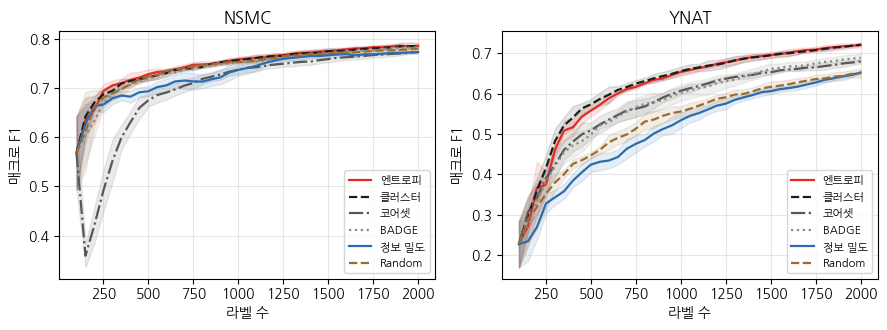

In [10]:
# ── 학습 곡선 ────
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, (name, r) in zip(axes, res.items()):
    plot_curves(r[r.strategy.isin(["BADGE", "엔트로피", "코어셋", "클러스터", "정보 밀도", "Random"])], "f1", ax, name.upper())
fig.tight_layout()
fig.savefig("out/ch08_curves.png", dpi=200)

전략별로 고른 배치의 중복을 비교한다. Random 배치의 중복이 기준이다.

                    R     dup
data strategy                
nsmc 엔트로피      0.0086  0.0316
     배깅5·KL    0.0342  0.2526
     클러스터      0.0077  0.0000
     코어셋       0.0120  0.0000
     BADGE     0.0087  0.0000
     정보 밀도     0.0238  0.0000
     Random    0.0094  0.0000
ynat 엔트로피      0.0061  0.0474
     배깅5·KL    0.0275  0.3316
     클러스터      0.0048  0.0053
     코어셋       0.0045  0.0000
     BADGE     0.0048  0.0000
     정보 밀도     0.0064  0.0000
     Random    0.0052  0.0000


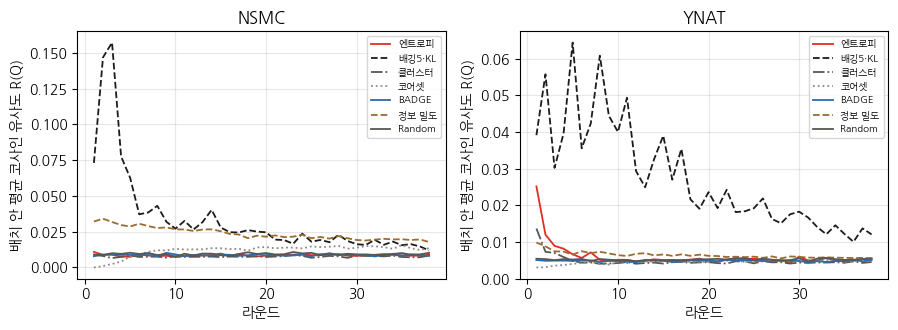

In [11]:
# ── 선택 배치의 중복 비교 ────
red = []
for name, d in DATA.items():
    for (strat, s), idx in orders[name].items():
        red.append(batch_redundancy(d["X_pool"], idx).assign(data=name, strategy=strat, seed=s))
red = pd.concat(red, ignore_index=True)
print(red.groupby(["data", "strategy"], sort=False)[["R", "dup"]].mean().round(4).to_string())

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, name in zip(axes, DATA):
    for (strat, g), (c, ls) in zip(red[red.data == name].groupby("strategy", sort=False), STYLES + [(GRAY, "-")]):
        m = g.groupby("round").R.mean()
        ax.plot(m.index + 1, m.values, color=c, ls=ls, lw=1.3, label=strat)
    ax.set(title=name.upper(), xlabel="라운드", ylabel="배치 안 평균 코사인 유사도 R(Q)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig("out/ch08_redundancy.png", dpi=200)

중복이 가장 큰 배치에서 근접 중복 쌍의 예시를 몇 개 출력한다.

In [12]:
# ── 근접 중복 예시 ────
for name, d in DATA.items():
    g = red[(red.data == name) & (red.seed == 0)]
    worst = g.sort_values("dup").iloc[-1]
    idx = orders[name][worst.strategy, 0]
    b = idx[N_INIT + int(worst["round"]) * K: N_INIT + (int(worst["round"]) + 1) * K]
    S = (d["X_pool"][b] @ d["X_pool"][b].T).toarray()
    iu = np.triu_indices(len(b), 1)
    print(f"\n{name}: {worst.strategy} {int(worst['round']) + 1}라운드, 근접 중복 쌍 {int(worst.dup)}개")
    for t in np.argsort(-S[iu])[:3]:
        i, j = iu[0][t], iu[1][t]
        print(f"  {S[i, j]:.3f} | {d['texts'][b[i]][:40]} | {d['texts'][b[j]][:40]}")


nsmc: 배깅5·KL 2라운드, 근접 중복 쌍 3개
  0.999 | ........ | .......
  0.995 | ............. | ........
  0.991 | ............. | .......

ynat: 배깅5·KL 20라운드, 근접 중복 쌍 3개
  0.971 | 이효성 방통위원장 PP업계 대표자 간담회 | 이효성 방통위원장PP업계 대표자 간담회
  0.938 | 동정 이효성 방통위원장 PP업계 대표자 간담회 | 이효성 방통위원장 PP업계 대표자 간담회
  0.912 | 동정 이효성 방통위원장 PP업계 대표자 간담회 | 이효성 방통위원장PP업계 대표자 간담회


## 8.6 배치 크기별 비교

배치 크기 k를 10, 50, 200으로 바꿔 다섯 전략을 비교한다. 예산은 2,000으로 같다. k = 10은 190라운드라 시드를 셋으로 줄인다. k = 50은 위 실험 결과를 그대로 쓴다.

In [13]:
# ── 배치 크기 실험 ────
SIZE_STRATS = ["Random", "엔트로피", "클러스터", "코어셋", "BADGE"]
rows = []
for name, d in DATA.items():
    for k, seeds in ((10, [0, 1, 2]), (50, SEEDS), (200, SEEDS)):
        r = res[name][res[name].strategy.isin(SIZE_STRATS)] if k == 50 else \
            run_strategies({s: STRATS[s] for s in SIZE_STRATS}, d, seeds=seeds, k=k)
        rows.append(summarize(r, "f1").assign(data=name, k=k))
batch = pd.concat(rows, ignore_index=True)
batch.to_csv("results/ch08_batch.csv", index=False)
print(batch.pivot_table(index=["data", "strategy"], columns="k", values="ALC", sort=False).round(4).to_string())

nsmc  Random, 엔트로피, 클러스터, 코어셋, BADGE 완료


nsmc  Random, 엔트로피, 클러스터, 코어셋, BADGE 완료


ynat  Random, 엔트로피, 클러스터, 코어셋, BADGE 완료


ynat  Random, 엔트로피, 클러스터, 코어셋, BADGE 완료
k                 10      50      200
data strategy                        
nsmc Random    0.7406  0.7426  0.7398
     엔트로피      0.7476  0.7479  0.7340
     클러스터      0.7460  0.7464  0.7360
     코어셋       0.7369  0.6998  0.6346
     BADGE     0.7406  0.7401  0.7405
ynat Random    0.5390  0.5335  0.5383
     엔트로피      0.6222  0.6164  0.5477
     클러스터      0.6255  0.6219  0.5884
     코어셋       0.5742  0.5761  0.5733
     BADGE     0.5903  0.5745  0.5624


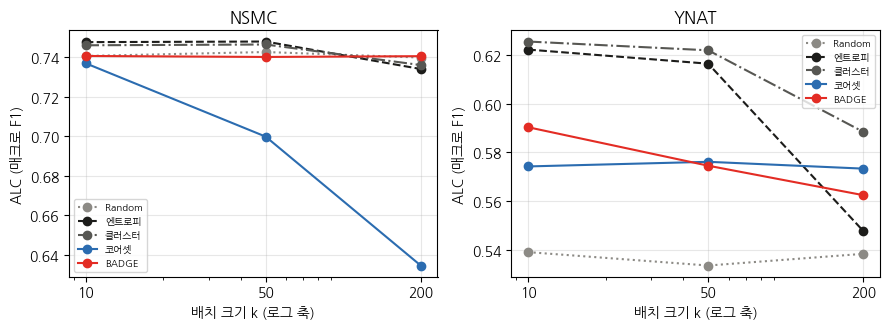

In [14]:
# ── 배치 크기 그림 ────
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, name in zip(axes, DATA):
    for (strat, g), (c, ls) in zip(batch[batch.data == name].groupby("strategy", sort=False), [(GRAY2, ":"), (INK, "--"), (GRAY, "-."), ("#2B6CB0", "-"), (ACCENT, "-")]):
        ax.plot(g.k, g.ALC, color=c, ls=ls, marker="o", lw=1.5, label=strat)
    ax.set(xscale="log", xticks=[10, 50, 200], xticklabels=["10", "50", "200"], title=name.upper(),
           xlabel="배치 크기 k (로그 축)", ylabel="ALC (매크로 F1)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig("out/ch08_batch_size.png", dpi=200)